In [ ]:
AGENT = "sac"
RUN = 1                                              # 0, 1 or 2

DRIVE_ROOT = "/content/drive/MyDrive/insulin-rl"       # results + shared warm-start data
CKPT_ROOT  = "/content/drive/MyDrive/insulin-rl-ckpt"  # checkpoints (resume after disconnect)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import os, torch
os.makedirs(f"{DRIVE_ROOT}/data", exist_ok=True)
os.makedirs("/content/code/common", exist_ok=True)
os.makedirs("/content/code/agents", exist_ok=True)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE. Switch the runtime to T4 GPU")

Mounted at /content/drive
GPU: Tesla T4


In [ ]:
# simglucose still imports pkg_resources, which setuptools >= 81 removed
!pip install -q "setuptools<81" simglucose
import warnings; warnings.filterwarnings("ignore")
import simglucose, pkg_resources
print("simglucose OK")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gymnasium>=1.0.0, but you have gymnasium 0.29.1 which is incompatible.
simglucose OK


## Code
Each cell below writes one source file to `/content/code`. Don't edit them: every run (on every PC) must use identical code.

In [ ]:
%%writefile /content/code/common/__init__.py
# package

Writing /content/code/common/__init__.py


In [ ]:
%%writefile /content/code/common/config.py
"""
Single source of truth for the experiment.

Every agent (SAC, SimbaV2, TD-MPC2, PPO) and every baseline imports these
values. Never copy a value from here into a notebook: change it here, in a new
code version folder (code/v2/...), and rerun every agent.
"""
import math

# ---------------------------------------------------------------- simulator
PATIENT = "adult#001"          # start with one adult; later loop over adult#001..010
SENSOR = "Dexcom"              # CGM reading every 3 minutes
PUMP = "Insulet"
SAMPLE_TIME = 3                # minutes per environment step (set by the sensor)
EPISODE_STEPS = 480            # 480 x 3 min = 24 h, starting at midnight

# ---------------------------------------------------------------- state
HISTORY_STEPS = 30             # 30 x 3 min = 90 min of history
MEAL_ANNOUNCE = True           # put carbs eaten in the state (same info basal-bolus uses)
TIME_FEATURES = True           # sin/cos of time of day
CGM_CENTER, CGM_SCALE = 140.0, 60.0   # cgm_norm = (CGM - 140) / 60
MEAL_SCALE_G = 50.0            # carbs_norm = grams eaten in the step / 50
CARB_EST_ERROR = 0.3           # patients misjudge carbs: announced = true x (1 + N(0, 0.3^2)).
                               # 0.0 = perfect carb counting (basal-bolus is then ~93% TIR, near ceiling)

# ---------------------------------------------------------------- action
# Agent outputs a in [-1, 1]. "direct" mapping to insulin rate (U/min), patient-relative:
#   a <= 0 : rate = basal * (1 + a)           (a = -1 -> 0, a = 0 -> basal)
#   a >  0 : rate = basal * MAX_MULT ** a     (a = 1  -> MAX_MULT x basal)
# The direct scale is also how past insulin is shown in the state, in both modes.
MAX_MULT = 40.0
ACTION_MODE = "residual"       # "direct" (agent chooses the dose) or "residual" (agent scales basal-bolus)
RES_MAX = 4.0                  # residual: rate = BB_rate * 4 ** a  ->  from BB/4 to 4 x BB

# ---------------------------------------------------------------- safety layer
SAFETY_ON = True               # applied to every RL agent (and to warm-start data)
SAFETY_SLOPE_WINDOW = 5        # last 5 CGM readings = 12 min for the slope fit
SAFETY_HORIZON_MIN = 30        # project glucose 30 min ahead
SAFETY_THRESHOLD = 80.0        # projected BG < 80 mg/dL -> insulin suspended (rate = 0)

# ---------------------------------------------------------------- reward
GAMMA = 0.99                   # effective horizon 1/(1-0.99) = 100 steps = 5 h
BG_LOW_TERMINATE = 10.0        # episode ends only at physiological extremes (simglucose's
BG_HIGH_TERMINATE = 600.0      # own limits); everything in between is punished by the risk reward


def _risk(bg):
    f = 1.509 * (math.log(bg) ** 1.084 - 5.381)
    return 10.0 * f * f


# Penalty must be worse than staying at the edge forever, otherwise ending the
# episode early would look attractive:  max(risk(10), risk(600)) / (1 - gamma) -> -19,300
TERMINATION_PENALTY = -math.ceil(
    max(_risk(BG_LOW_TERMINATE), _risk(BG_HIGH_TERMINATE)) / (1 - GAMMA) / 100) * 100

# ---------------------------------------------------------------- seeds (never overlap)
TRAIN_SEED_RANGE = (0, 5000)                    # a new random day per training episode
WARMSTART_SEEDS = list(range(5001, 5031))       # 30 days of basal-bolus data
WARMSTART_NOISE = 0.2                           # exploration noise on the warm-start actions
EVAL_SEEDS = list(range(9001, 9011))            # 10 held-out days, used by EVERY agent
TRAIN_RUNS = [0, 1, 2]                          # 3 independent training runs per agent

# ---------------------------------------------------------------- warm start (same for every agent)
# Every agent starts from the same 30 days of basal-bolus data before it touches the patient.
WARMSTART_BC_STEPS = 5_000     # 1) behaviour-clone the actor / policy prior on those transitions
WARMSTART_CRITIC_STEPS = 5_000 # 2) fit the critic(s) (and TD-MPC2's world model), policy frozen

# ---------------------------------------------------------------- training budget
STEP_BUDGET = 100_000          # environment steps per run (~208 simulated days)
EVAL_EVERY = 10_000            # learning-curve point every 10k steps
CKPT_EVERY = 10_000            # checkpoint to Drive every 10k steps (Colab disconnects)

# ---------------------------------------------------------------- basal-bolus rule (residual base + warm start)
BB_TARGET = 140.0              # correction target
BB_CORRECTION_ABOVE = 150.0    # correction bolus only if CGM > 150 (simglucose rule)


def as_dict():
    """All upper-case settings, saved into every run's meta.json."""
    return {k: v for k, v in globals().items() if k.isupper()}

Writing /content/code/common/config.py


In [ ]:
%%writefile /content/code/common/rewards.py
"""
Reward = negative glucose risk index (Kovatchev / Magni form, same as simglucose).

    f(BG)  = 1.509 * ((ln BG)^1.084 - 5.381)
    risk   = 10 * f^2
    r_t    = -risk(BG_{t+1})            (+ TERMINATION_PENALTY if the episode ends)

risk is ~0 at 112 mg/dL, 7.75 at 70, 7.74 at 180, 18.4 at 54, 22.4 at 250:
lows are punished much more steeply than highs.
"""
import numpy as np
from . import config


def risk(bg):
    bg = np.maximum(np.asarray(bg, dtype=np.float64), 1.0)
    f = 1.509 * (np.log(bg) ** 1.084 - 5.381)
    return 10.0 * f * f


def lbgi_hbgi(bg):
    """Low / High Blood Glucose Index of a trace (risk split by side of 112)."""
    bg = np.maximum(np.asarray(bg, dtype=np.float64), 1.0)
    f = 1.509 * (np.log(bg) ** 1.084 - 5.381)
    r = 10.0 * f * f
    return float(np.mean(np.where(f < 0, r, 0.0))), float(np.mean(np.where(f > 0, r, 0.0)))


def reward(bg_next, terminated):
    r = -float(risk(bg_next))
    if terminated:
        r += config.TERMINATION_PENALTY
    return r

Writing /content/code/common/rewards.py


In [ ]:
%%writefile /content/code/common/safety.py
"""
Safety layer: predictive low-glucose suspend.

1. Fit a straight line to the last SAFETY_SLOPE_WINDOW CGM readings
   (least squares, x in minutes)  ->  slope in mg/dL per minute.
2. Project 30 minutes ahead:  BG_pred = CGM_now + slope * 30
3. If BG_pred < 80 mg/dL, override the agent: insulin rate = 0.

Example: last readings 120, 114, 108, 102, 96 (3 min apart)
  slope = -2 mg/dL/min, BG_pred = 96 + (-2)(30) = 36 < 80  -> suspend.
"""
import numpy as np
from . import config


def projected_bg(cgm_history):
    y = np.asarray(cgm_history[-config.SAFETY_SLOPE_WINDOW:], dtype=np.float64)
    if len(y) < 2:
        return float(y[-1])
    x = np.arange(len(y)) * config.SAMPLE_TIME
    slope = np.polyfit(x, y, 1)[0]
    return float(y[-1] + slope * config.SAFETY_HORIZON_MIN)


def apply(rate_proposed, cgm_history):
    """Returns (rate_executed, overridden, bg_pred)."""
    bg_pred = projected_bg(cgm_history)
    if bg_pred < config.SAFETY_THRESHOLD and rate_proposed > 0.0:
        return 0.0, True, bg_pred
    return float(rate_proposed), False, bg_pred

Writing /content/code/common/safety.py


In [ ]:
%%writefile /content/code/common/env.py
"""
Gymnasium wrapper around simglucose (UVA/Padova T1D simulator).

One step = 3 minutes. One episode = 24 h starting at midnight = 480 steps.

State (92 numbers with the default config):
    30 x CGM            (CGM - 140) / 60                              last 90 min
    30 x insulin        executed rate on the "direct" scale, in [-1, 1] last 90 min
    30 x carbs          ANNOUNCED grams in the step / 50              last 90 min  (MEAL_ANNOUNCE)
     2 x time of day    sin, cos of 2*pi*minute/1440                               (TIME_FEATURES)

Action a in [-1, 1] -> insulin rate (U/min). Two modes (config.ACTION_MODE):

  "direct"    the agent chooses the whole dose, patient-relative:
                a <= 0 : rate = basal * (1 + a)              a = -1 -> 0,  a = 0 -> basal
                a >  0 : rate = basal * MAX_MULT ** a        a = 1  -> 40 x basal

  "residual"  the agent scales what basal-bolus would give right now:
                rate = BB_rate * RES_MAX ** a                a = 0 -> exactly basal-bolus
                                                              a = -1 -> BB / 4,  a = +1 -> BB x 4
              BB_rate = basal + bolus/3, bolus = carbs/CR + [CGM>150](CGM-140)/CF at meals.

Carb counting: the simulator eats the TRUE carbs, but the state and basal-bolus
only see the patient's estimate, true x (1 + N(0, CARB_EST_ERROR^2)), one error per
meal (seeded by the day, so every agent faces the same errors on the same day).

Every step passes through the safety layer (if enabled). info["a_exec"] is the
action that was actually delivered (in the active mode): replay buffers store
that, not the proposed action.
"""
import importlib.resources
import logging
import math
import warnings
from datetime import datetime

import gymnasium as gym
import numpy as np
import pandas as pd

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    from simglucose.actuator.pump import InsulinPump
    from simglucose.controller.base import Action
    from simglucose.patient.t1dpatient import T1DPatient
    from simglucose.sensor.cgm import CGMSensor
    from simglucose.simulation.env import T1DSimEnv
    from simglucose.simulation.scenario_gen import RandomScenario

from . import config, rewards, safety

logging.getLogger("simglucose").setLevel(logging.WARNING)
START_TIME = datetime(2026, 1, 1, 0, 0)


def _param_table(name):
    path = importlib.resources.files("simglucose") / "params" / name
    return pd.read_csv(str(path))


def patient_params(patient):
    """basal (U/min), carb ratio CR (g/U), correction factor CF (mg/dL per U)."""
    vp = _param_table("vpatient_params.csv")
    q = _param_table("Quest.csv")
    row = vp[vp.Name == patient].iloc[0]
    qrow = q[q.Name == patient].iloc[0]
    return {"basal": float(row.u2ss * row.BW / 6000.0), "CR": float(qrow.CR),
            "CF": float(qrow.CF), "BW": float(row.BW)}


def basal_bolus_rate(params, meal_gpm, cgm):
    """simglucose's basal-bolus rule. meal_gpm = average carb intake over the last step (g/min)."""
    bolus = 0.0
    if meal_gpm > 0:
        bolus = meal_gpm * config.SAMPLE_TIME / params["CR"]
        if cgm > config.BB_CORRECTION_ABOVE:
            bolus += (cgm - config.BB_TARGET) / params["CF"]
    return params["basal"] + bolus / config.SAMPLE_TIME


class GlucoseEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(self, patient=config.PATIENT, safety_on=config.SAFETY_ON, action_mode=None):
        super().__init__()
        self.patient_name = patient
        self.safety_on = safety_on
        self.action_mode = action_mode or config.ACTION_MODE
        assert self.action_mode in ("direct", "residual")
        self.params = patient_params(patient)
        self.basal = self.params["basal"]

        self._patient = T1DPatient.withName(patient)
        self._sensor = CGMSensor.withName(config.SENSOR, seed=0)
        self._pump = InsulinPump.withName(config.PUMP)
        self._scenario = RandomScenario(start_time=START_TIME, seed=0)
        self._sim = T1DSimEnv(self._patient, self._sensor, self._pump, self._scenario)

        H = config.HISTORY_STEPS
        dim = 2 * H + (H if config.MEAL_ANNOUNCE else 0) + (2 if config.TIME_FEATURES else 0)
        self.observation_space = gym.spaces.Box(-np.inf, np.inf, (dim,), np.float32)
        self.action_space = gym.spaces.Box(-1.0, 1.0, (1,), np.float32)
        self.t = 0
        self.bb_rate = self.basal

    # ------------------------------------------------------------ action maps
    def direct_rate(self, a):
        a = float(np.clip(a, -1.0, 1.0))
        return self.basal * (1.0 + a) if a <= 0.0 else self.basal * config.MAX_MULT ** a

    def direct_action(self, rate):
        if rate <= self.basal:
            return float(np.clip(rate / self.basal - 1.0, -1.0, 0.0))
        return float(np.clip(math.log(rate / self.basal) / math.log(config.MAX_MULT), 0.0, 1.0))

    def rate_from_action(self, a):
        if self.action_mode == "direct":
            return self.direct_rate(a)
        return self.bb_rate * config.RES_MAX ** float(np.clip(a, -1.0, 1.0))

    def action_from_rate(self, rate):
        if self.action_mode == "direct":
            return self.direct_action(rate)
        if rate <= 0.0:
            return -1.0
        return float(np.clip(math.log(rate / self.bb_rate) / math.log(config.RES_MAX), -1.0, 1.0))

    # ------------------------------------------------------------ gym API
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        s = int(seed) if seed is not None else int(self.np_random.integers(*config.TRAIN_SEED_RANGE))
        self._scenario.seed = s
        self._sensor.seed = s
        obs0, _, _, info0 = self._sim.reset()
        self.t = 0
        H = config.HISTORY_STEPS
        cgm0 = float(obs0.CGM)
        self.cgm_hist = [cgm0] * H
        self.ins_hist = [0.0] * H          # 0 on the direct scale = basal
        self.meal_hist = [0.0] * H
        self.bb_rate = basal_bolus_rate(self.params, 0.0, cgm0)
        self._carb_rng = np.random.default_rng(1_000_000 + s)   # same errors for the same day
        self._carb_factor, self._prev_meal_true = 1.0, 0.0
        info = {"cgm": cgm0, "bg": float(info0["bg"]), "meal": 0.0, "scenario_seed": s,
                "minute": self._minute(), "bb_rate": self.bb_rate, "overridden": False}
        return self._obs(), info

    def step(self, action):
        a = float(np.asarray(action).reshape(-1)[0])
        info = self._advance(self.rate_from_action(a))
        info["a_proposed"] = float(np.clip(a, -1.0, 1.0))
        return info.pop("_obs"), info.pop("_r"), info.pop("_term"), info.pop("_trunc"), info

    def step_rate(self, rate):
        """For clinical baselines that compute an insulin rate (U/min) directly."""
        info = self._advance(max(float(rate), 0.0))
        return info.pop("_obs"), info.pop("_r"), info.pop("_term"), info.pop("_trunc"), info

    # ------------------------------------------------------------ internals
    def _advance(self, rate_proposed):
        if self.safety_on:
            rate_exec, overridden, bg_pred = safety.apply(rate_proposed, self.cgm_hist)
        else:
            rate_exec, overridden, bg_pred = rate_proposed, False, float("nan")
        a_exec = self.action_from_rate(rate_exec)       # relative to the BB rate used for THIS decision

        sg_obs, _, _, sg_info = self._sim.step(Action(basal=rate_exec, bolus=0.0))
        bg = float(sg_info["bg"])
        cgm = float(sg_obs.CGM)
        meal_true = float(sg_info["meal"])   # average carb intake during this step (g/min)
        if meal_true > 0 and self._prev_meal_true == 0:          # a new meal: draw its counting error
            self._carb_factor = max(0.2, 1.0 + self._carb_rng.normal(0.0, config.CARB_EST_ERROR))
        self._prev_meal_true = meal_true
        meal = meal_true * self._carb_factor  # what the patient announces (state + basal-bolus)
        self.t += 1

        terminated = bg < config.BG_LOW_TERMINATE or bg > config.BG_HIGH_TERMINATE
        truncated = (self.t >= config.EPISODE_STEPS) and not terminated
        r = rewards.reward(bg, terminated)

        self.cgm_hist = self.cgm_hist[1:] + [cgm]
        self.ins_hist = self.ins_hist[1:] + [self.direct_action(rate_exec)]
        self.meal_hist = self.meal_hist[1:] + [meal]
        self.bb_rate = basal_bolus_rate(self.params, meal, cgm)   # reference for the NEXT decision

        return {
            "_obs": self._obs(), "_r": r, "_term": terminated, "_trunc": truncated,
            "bg": bg, "cgm": cgm, "meal": meal, "meal_true": meal_true, "minute": self._minute(),
            "rate_proposed": float(rate_proposed), "rate_exec": float(rate_exec),
            "insulin_U": float(rate_exec) * config.SAMPLE_TIME, "bb_rate": self.bb_rate,
            "a_exec": a_exec, "overridden": bool(overridden), "bg_pred": bg_pred,
        }

    def _minute(self):
        tm = self._sim.time
        return tm.hour * 60 + tm.minute

    def _obs(self):
        parts = [(np.asarray(self.cgm_hist) - config.CGM_CENTER) / config.CGM_SCALE,
                 np.asarray(self.ins_hist)]
        if config.MEAL_ANNOUNCE:
            parts.append(np.asarray(self.meal_hist) * config.SAMPLE_TIME / config.MEAL_SCALE_G)
        if config.TIME_FEATURES:
            ang = 2.0 * math.pi * self._minute() / 1440.0
            parts.append(np.array([math.sin(ang), math.cos(ang)]))
        return np.concatenate(parts).astype(np.float32)

Writing /content/code/common/env.py


In [ ]:
%%writefile /content/code/common/metrics.py
"""
Standard glycaemic outcome measures, computed on the TRUE blood glucose trace
(one value per 3-min step).

    TIR     % time 70-180 mg/dL           (primary, higher is better)
    TBR54   % time < 54 mg/dL             (primary safety, lower is better)
    TBR70   % time < 70
    TAR180  % time > 180
    TAR250  % time > 250
    CV      std / mean * 100              (variability; < 36% is the clinical target)
    LBGI / HBGI                           low / high blood glucose index

If an episode terminates early (BG < 40 or > 350) the remaining steps of the
day are counted at the failing BG value, so a crash can never improve TIR.
"""
import numpy as np
from . import config
from .rewards import lbgi_hbgi, risk


def episode_metrics(bg, overridden, insulin_U, terminated):
    bg = np.asarray(bg, dtype=np.float64)
    steps_run = len(bg)
    if terminated and steps_run < config.EPISODE_STEPS:
        bg = np.concatenate([bg, np.full(config.EPISODE_STEPS - steps_run, bg[-1])])
    lbgi, hbgi = lbgi_hbgi(bg)
    pct = lambda m: float(100.0 * np.mean(m))
    return {
        "TIR": pct((bg >= 70) & (bg <= 180)),
        "TBR54": pct(bg < 54),
        "TBR70": pct(bg < 70),
        "TAR180": pct(bg > 180),
        "TAR250": pct(bg > 250),
        "mean_BG": float(bg.mean()),
        "CV": float(100.0 * bg.std() / bg.mean()),
        "min_BG": float(bg.min()),
        "max_BG": float(bg.max()),
        "LBGI": lbgi,
        "HBGI": hbgi,
        "mean_risk": float(np.mean(risk(bg))),
        "override_rate": pct(np.asarray(overridden, dtype=bool)) if len(overridden) else 0.0,
        "total_insulin_U": float(np.sum(insulin_U)),
        "terminated": bool(terminated),
        "steps_run": int(steps_run),
    }


def summarize(per_seed):
    """mean and std across evaluation days."""
    keys = [k for k in per_seed[0] if k not in ("terminated", "steps_run", "seed")]
    out = {}
    for k in keys:
        v = np.array([m[k] for m in per_seed], dtype=np.float64)
        out[k] = float(v.mean())
        out[k + "_std"] = float(v.std())
    out["n_terminated"] = int(sum(m["terminated"] for m in per_seed))
    out["n_days"] = len(per_seed)
    return out

Writing /content/code/common/metrics.py


In [ ]:
%%writefile /content/code/common/evaluate.py
"""
Run any policy on a list of days (default: the 10 held-out EVAL_SEEDS).

A policy is any object with `kind` ("action" or "rate"), `reset()` and
`__call__(obs, info)`. RL agents are wrapped with `AgentPolicy`, which always
uses the deterministic action (mean of the policy).
"""
from . import config, metrics


class AgentPolicy:
    kind = "action"

    def __init__(self, agent):
        self.agent = agent

    def reset(self):
        if hasattr(self.agent, "reset"):
            self.agent.reset()

    def __call__(self, obs, info):
        return self.agent.act(obs, deterministic=True)


def run_day(policy, env, seed, keep_trace=False):
    obs, info = env.reset(seed=seed)
    policy.reset()
    bg, ovr, ins, trace = [], [], [], []
    terminated = truncated = False
    while not (terminated or truncated):
        u = policy(obs, info)
        if policy.kind == "rate":
            obs, r, terminated, truncated, info = env.step_rate(u)
        else:
            obs, r, terminated, truncated, info = env.step(u)
        bg.append(info["bg"])
        ovr.append(info["overridden"])
        ins.append(info["insulin_U"])
        if keep_trace:
            trace.append({k: info[k] for k in ("minute", "bg", "cgm", "meal", "rate_exec", "overridden")})
    m = metrics.episode_metrics(bg, ovr, ins, terminated)
    m["seed"] = int(seed)
    return (m, trace) if keep_trace else m


def evaluate_policy(policy, env, seeds=None):
    seeds = config.EVAL_SEEDS if seeds is None else seeds
    per_seed = [run_day(policy, env, s) for s in seeds]
    return {"per_seed": per_seed, "summary": metrics.summarize(per_seed)}

Writing /content/code/common/evaluate.py


In [ ]:
%%writefile /content/code/common/baselines.py
"""
Basal-bolus, used here only to create the warm-start data.

    bolus (U) = carbs / CR  +  [CGM > 150] * (CGM - 140) / CF      when a meal is announced
    rate      = basal + bolus / 3                                  (spread over the 3-min step)
"""
import numpy as np

from . import config
from .env import basal_bolus_rate


class BasalBolus:
    kind = "rate"

    def __init__(self, env):
        self.params = env.params
        self.basal = env.basal

    def reset(self):
        pass

    def __call__(self, obs, info):
        return basal_bolus_rate(self.params, info["meal"], info["cgm"])


class BasalBolusAction(BasalBolus):
    """Basal-bolus in the agent's action space.

    residual mode: a = 0 is exactly basal-bolus.
    direct mode:   a large bolus that does not fit in one step (max 40 x basal)
                   is carried over to the next steps; cancelled if the safety layer suspends.

    noise > 0 adds a + N(0, noise^2), so the critics see what a bit more or less
    insulin than basal-bolus does. Without it, every warm-start action at a meal
    is the same and the critic cannot learn how the dose changes the outcome."""
    kind = "action"

    def __init__(self, env, noise=0.0, rng=None):
        super().__init__(env)
        self.env, self.noise = env, noise
        self.rng = rng if rng is not None else np.random.default_rng(0)
        self.reset()

    def reset(self):
        self.pending_U = 0.0

    def __call__(self, obs, info):
        if self.env.action_mode == "residual":
            a = 0.0
        else:
            if info.get("overridden"):
                self.pending_U = 0.0
            dt = config.SAMPLE_TIME
            want_U = (super().__call__(obs, info) - self.basal) * dt + self.pending_U
            give_U = min(want_U, (self.env.direct_rate(1.0) - self.basal) * dt)
            self.pending_U = want_U - give_U
            a = self.env.action_from_rate(self.basal + give_U / dt)
        if self.noise > 0:
            a = float(np.clip(a + self.rng.normal(0.0, self.noise), -1.0, 1.0))
        return a

Writing /content/code/common/baselines.py


In [ ]:
%%writefile /content/code/common/warmstart.py
"""
Warm-start data: basal-bolus (+ small exploration noise) for 30 days
(WARMSTART_SEEDS) through the SAME environment the RL agents use
(action map + safety layer + carb errors).

Each transition is (s, a_exec, r, s', terminated, ep_end). The end of a day is
truncation, not termination, so critics still bootstrap there.

30 days x 480 steps = 14,400 transitions (~11 MB). The first notebook to run
creates it on Drive; every other run loads the same file.
"""
import os

import numpy as np

from . import config
from .baselines import BasalBolusAction
from .env import GlucoseEnv


def generate(path):
    env = GlucoseEnv(safety_on=config.SAFETY_ON)
    pol = BasalBolusAction(env, noise=config.WARMSTART_NOISE, rng=np.random.default_rng(777))
    O, A, R, O2, D, E = [], [], [], [], [], []
    for seed in config.WARMSTART_SEEDS:
        obs, info = env.reset(seed=seed)
        pol.reset()
        term = trunc = False
        while not (term or trunc):
            a = pol(obs, info)
            obs2, r, term, trunc, info = env.step(a)
            O.append(obs); A.append([info["a_exec"]]); R.append(r); O2.append(obs2)
            D.append(float(term)); E.append(term or trunc)
            obs = obs2
    data = {k: np.asarray(v, dtype=np.float32) for k, v in
            dict(obs=O, act=A, rew=R, next_obs=O2, done=D).items()}
    data["ep_end"] = np.asarray(E, dtype=np.bool_)
    tmp = path + ".tmp.npz"
    np.savez(tmp, action_mode=np.array(config.ACTION_MODE), **data)
    os.replace(tmp, path)          # atomic: two PCs creating it at once can't corrupt it
    print(f"saved {len(R)} transitions to {path} (mean reward {np.mean(R):.2f})")
    return data


def load(path):
    d = np.load(path)
    mode = str(d["action_mode"])
    if mode != config.ACTION_MODE:
        raise ValueError(f"{path} was generated for ACTION_MODE={mode!r} but config says "
                         f"{config.ACTION_MODE!r}; delete it so it is regenerated")
    return {k: d[k] for k in d.files if k != "action_mode"}

Writing /content/code/common/warmstart.py


In [ ]:
%%writefile /content/code/common/replay.py
"""Replay buffer shared by all three agents.

Transitions are stored in time order. `ep_end` marks the last step of a day
(terminated OR truncated), so TD-MPC2 can sample short contiguous sequences that
never cross from one day into the next.
"""
import numpy as np
import torch


class ReplayBuffer:
    def __init__(self, obs_dim, act_dim, capacity):
        self.capacity = int(capacity)
        self.obs = np.zeros((self.capacity, obs_dim), np.float32)
        self.act = np.zeros((self.capacity, act_dim), np.float32)
        self.rew = np.zeros((self.capacity, 1), np.float32)
        self.next_obs = np.zeros((self.capacity, obs_dim), np.float32)
        self.done = np.zeros((self.capacity, 1), np.float32)      # terminated (no bootstrap)
        self.ep_end = np.zeros((self.capacity,), np.bool_)         # terminated or truncated
        self.ptr = 0
        self.size = 0

    def add(self, o, a, r, o2, d, ep_end):
        i = self.ptr
        self.obs[i], self.act[i], self.rew[i], self.next_obs[i], self.done[i] = o, a, r, o2, d
        self.ep_end[i] = ep_end
        self.ptr = (self.ptr + 1) % self.capacity
        self.size = min(self.size + 1, self.capacity)

    def add_many(self, data):
        for o, a, r, o2, d, e in zip(data["obs"], data["act"], data["rew"], data["next_obs"],
                                     data["done"], data["ep_end"]):
            self.add(o, a, r, o2, d, e)

    def sample(self, batch_size, device, rng, hi=None):
        """Independent transitions. hi: sample only from the first `hi` (the warm-start data)."""
        idx = rng.integers(0, self.size if hi is None else hi, size=batch_size)
        t = lambda x: torch.as_tensor(x[idx], device=device)
        return t(self.obs), t(self.act), t(self.rew), t(self.next_obs), t(self.done)

    def sample_seq(self, batch_size, horizon, device, rng, hi=None):
        """Contiguous sequences of `horizon` transitions inside one day.
        Returns obs0 (B, obs), act (H, B, A), rew (H, B, 1), next_obs (H, B, obs), done (H, B, 1)."""
        n = (self.size if hi is None else hi) - horizon + 1
        starts = []
        while len(starts) < batch_size:
            cand = rng.integers(0, n, size=2 * batch_size)
            # a sequence is valid if no day ends before its last transition
            ok = ~np.any(np.stack([self.ep_end[cand + k] for k in range(horizon - 1)]), axis=0) \
                if horizon > 1 else np.ones(len(cand), bool)
            starts.extend(cand[ok].tolist())
        s = np.asarray(starts[:batch_size])
        idx = s[None, :] + np.arange(horizon)[:, None]                 # (H, B)
        t = lambda x: torch.as_tensor(x[idx], device=device)
        return (torch.as_tensor(self.obs[s], device=device), t(self.act), t(self.rew),
                t(self.next_obs), t(self.done))

    def save(self, path):
        n = self.size
        np.savez(path, obs=self.obs[:n], act=self.act[:n], rew=self.rew[:n],
                 next_obs=self.next_obs[:n], done=self.done[:n], ep_end=self.ep_end[:n], ptr=self.ptr)

    def load(self, path):
        d = np.load(path)
        n = len(d["rew"])
        self.obs[:n], self.act[:n], self.rew[:n] = d["obs"], d["act"], d["rew"]
        self.next_obs[:n], self.done[:n], self.ep_end[:n] = d["next_obs"], d["done"], d["ep_end"]
        self.size, self.ptr = n, int(d["ptr"])

Writing /content/code/common/replay.py


In [ ]:
%%writefile /content/code/common/utils.py
"""Small helpers: code fingerprints (replaces git commit hashes) and JSON I/O."""
import hashlib
import json
import pathlib


def code_hash(root):
    """sha256 over every .py file under root (sorted by path). 12 hex chars."""
    root = pathlib.Path(root)
    h = hashlib.sha256()
    for f in sorted(root.rglob("*.py")):
        h.update(str(f.relative_to(root)).encode())
        h.update(f.read_bytes())
    return h.hexdigest()[:12]


def code_hashes(code_root):
    """common_hash must be identical across every agent's runs."""
    code_root = pathlib.Path(code_root)
    return {"common_hash": code_hash(code_root / "common"),
            "agents_hash": code_hash(code_root / "agents")}


def save_json(path, obj):
    with open(path, "w") as f:
        json.dump(obj, f, indent=2, default=float)


def load_json(path):
    with open(path) as f:
        return json.load(f)

Writing /content/code/common/utils.py


In [ ]:
%%writefile /content/code/common/trainer.py
"""
Training loop shared by SAC, SimbaV2 and TD-MPC2, so the agent is the only
thing that differs between runs.

An agent provides:
    act(obs, deterministic)          -> a in [-1, 1]
    warm_start(buffer, rng, n_warm)  -> learn from the basal-bolus data before any env step
    train_step(buffer, rng)          -> gradient update(s) after every env step, returns stats
    reset()                          -> start of a new day (TD-MPC2 forgets its last plan)
    observe(obs, r, ep_end)          -> optional, every env step (SimbaV2's running statistics)
    state_dict() / load_state_dict()
    batch_size, device, hparams

Loop:
    1. pre-fill the buffer with the warm-start transitions, agent.warm_start(...)
    2. every env step: a ~ policy -> safety layer -> simulator
                       store (s, a_EXECUTED, r, s', terminated, end-of-day), agent.train_step(...)
    3. every EVAL_EVERY steps: deterministic policy on the 10 held-out days -> curve.csv
    4. every CKPT_EVERY steps: agent + buffer + RNG states to Drive (resume after a disconnect)
    5. end: final_eval.json, meta.json, agent_final.pt

Results:      {results_dir}/{agent}/run_{k}/
Checkpoints:  {ckpt_dir}/{agent}/run_{k}/ckpt.pt, buffer.npz
"""
import csv
import os
import platform
import random
import time

import numpy as np
import torch

from . import config
from .env import GlucoseEnv
from .evaluate import AgentPolicy, evaluate_policy
from .replay import ReplayBuffer
from .utils import code_hashes, load_json, save_json
from .warmstart import load as load_warmstart

CURVE_FIELDS = ["step", "TIR", "TBR54", "TBR70", "TAR180", "TAR250", "mean_BG", "CV",
                "mean_risk", "override_rate", "n_terminated", "wall_min"]


def _curve_row(step, summary, wall_min):
    row = {"step": step, "wall_min": round(wall_min, 2)}
    row.update({k: round(summary[k], 4) for k in CURVE_FIELDS if k in summary})
    return row


def _write_curve(path, rows):
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=CURVE_FIELDS)
        w.writeheader()
        w.writerows(rows)


def _read_curve(path):
    if not os.path.exists(path):
        return []
    with open(path) as f:
        return [{k: float(v) for k, v in r.items()} for r in csv.DictReader(f)]


def _evaluate(agent, env, seeds):
    s = evaluate_policy(AgentPolicy(agent), env, seeds)
    agent.reset()
    return s


def train(agent_name, make_agent, run, results_dir, ckpt_dir, code_root, warmstart_path,
          step_budget=None, eval_every=None, ckpt_every=None, eval_seeds=None, device=None,
          log_every=2400):
    step_budget = step_budget or config.STEP_BUDGET
    eval_every = eval_every or config.EVAL_EVERY
    ckpt_every = ckpt_every or config.CKPT_EVERY
    eval_seeds = eval_seeds or config.EVAL_SEEDS
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    if device == "cpu":
        torch.set_num_threads(1)   # the simulator is single-threaded; extra torch threads only contend

    out_dir = os.path.join(results_dir, agent_name, f"run_{run}")
    ck_dir = os.path.join(ckpt_dir, agent_name, f"run_{run}")
    os.makedirs(out_dir, exist_ok=True)
    os.makedirs(ck_dir, exist_ok=True)
    ckpt_path, buf_path = os.path.join(ck_dir, "ckpt.pt"), os.path.join(ck_dir, "buffer.npz")
    curve_path = os.path.join(out_dir, "curve.csv")

    if os.path.exists(os.path.join(out_dir, "final_eval.json")):
        print(f"{agent_name} run_{run} already finished -> {out_dir}")
        return load_json(os.path.join(out_dir, "final_eval.json"))

    # ---- seeding: run k is fully determined by k
    random.seed(run)
    np.random.seed(run)
    torch.manual_seed(run)
    ep_rng = np.random.default_rng(10_000 + run)      # which training day comes next
    sample_rng = np.random.default_rng(20_000 + run)  # replay sampling

    env = GlucoseEnv(safety_on=config.SAFETY_ON)
    eval_env = GlucoseEnv(safety_on=config.SAFETY_ON)
    obs_dim, act_dim = env.observation_space.shape[0], env.action_space.shape[0]
    agent = make_agent(obs_dim, act_dim, device)

    warm = load_warmstart(warmstart_path)
    n_warm = len(warm["rew"])            # warm-start data sits at buffer indices [0, n_warm)
    buffer = ReplayBuffer(obs_dim, act_dim, step_budget + n_warm)

    step, wall_before, curve = 0, 0.0, []
    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        agent.load_state_dict(ck["agent"])
        buffer.load(buf_path)
        step, wall_before = ck["step"], ck["wall_sec"]
        ep_rng.bit_generator.state = ck["ep_rng"]
        sample_rng.bit_generator.state = ck["sample_rng"]
        torch.set_rng_state(ck["torch_rng"])
        curve = [r for r in _read_curve(curve_path) if r["step"] <= step]
        print(f"resumed {agent_name} run_{run} at step {step:,}")
    else:
        buffer.add_many(warm)
        print(f"{agent_name} run_{run}: buffer pre-filled with {buffer.size:,} basal-bolus transitions")
        t0 = time.time()
        msg = agent.warm_start(buffer, sample_rng, n_warm)
        print(f"warm start: {msg} [{time.time()-t0:.0f}s]")
        t0 = time.time()
        s = _evaluate(agent, eval_env, eval_seeds)["summary"]
        curve = [_curve_row(0, s, 0.0)]
        _write_curve(curve_path, curve)
        print(f"step 0 (after warm start): TIR {s['TIR']:.1f}  TBR54 {s['TBR54']:.2f}  [{time.time()-t0:.0f}s eval]")

    t_start = time.time()
    wall = lambda: wall_before + time.time() - t_start
    obs, info = env.reset(seed=int(ep_rng.integers(*config.TRAIN_SEED_RANGE)))
    agent.reset()
    ep_ret, ep_bg, ep_ovr, last_stats, log_t, log_step = 0.0, [], 0, {}, time.time(), step

    while step < step_budget:
        a = agent.act(obs, deterministic=False)
        obs2, r, term, trunc, info = env.step(a)
        buffer.add(obs, [info["a_exec"]], r, obs2, float(term), term or trunc)
        if hasattr(agent, "observe"):
            agent.observe(obs2, r, term or trunc)
        obs = obs2
        step += 1
        ep_ret += r
        ep_bg.append(info["bg"])
        ep_ovr += info["overridden"]

        last_stats = agent.train_step(buffer, sample_rng)

        if term or trunc:
            bg = np.array(ep_bg)
            tir = 100 * np.mean((bg >= 70) & (bg <= 180))
            if step % log_every < len(bg) or term:
                sps = (step - log_step) / max(time.time() - log_t, 1e-9)
                stats = " | ".join(f"{k} {v:.3g}" for k, v in last_stats.items())
                print(f"step {step:7,} | day return {ep_ret:8.1f} | TIR {tir:5.1f} | min BG {bg.min():5.1f}"
                      f" | {'CRASH ' if term else ''}overrides {ep_ovr:3d} | {stats} | {sps:4.0f} steps/s")
                log_t, log_step = time.time(), step
            obs, info = env.reset(seed=int(ep_rng.integers(*config.TRAIN_SEED_RANGE)))
            agent.reset()
            ep_ret, ep_bg, ep_ovr = 0.0, [], 0

        if step % eval_every == 0:
            t0 = time.time()
            s = _evaluate(agent, eval_env, eval_seeds)["summary"]
            curve.append(_curve_row(step, s, wall() / 60))
            _write_curve(curve_path, curve)
            print(f"== eval @ {step:,}: TIR {s['TIR']:.1f} ± {s['TIR_std']:.1f} | TBR54 {s['TBR54']:.2f}"
                  f" | TBR70 {s['TBR70']:.2f} | TAR180 {s['TAR180']:.1f} | overrides {s['override_rate']:.1f}%"
                  f" | crashes {s['n_terminated']} [{time.time()-t0:.0f}s]")

        if step % ckpt_every == 0 or step == step_budget:
            tmp = ckpt_path + ".tmp"
            torch.save({"agent": agent.state_dict(), "step": step, "wall_sec": wall(),
                        "ep_rng": ep_rng.bit_generator.state, "sample_rng": sample_rng.bit_generator.state,
                        "torch_rng": torch.get_rng_state()}, tmp)
            buffer.save(buf_path + ".tmp.npz")
            os.replace(buf_path + ".tmp.npz", buf_path)
            os.replace(tmp, ckpt_path)
            # a day in progress is abandoned on resume; its transitions are already in the buffer

    # ---- final evaluation of the final policy (no checkpoint picking on held-out days)
    res = _evaluate(agent, eval_env, eval_seeds)
    torch.save(agent.state_dict(), os.path.join(out_dir, "agent_final.pt"))
    save_json(os.path.join(out_dir, "final_eval.json"), res)
    gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
    save_json(os.path.join(out_dir, "meta.json"), {
        "agent": agent_name, "run": run, **code_hashes(code_root),
        "hparams": getattr(agent, "hparams", {}), "config": config.as_dict(),
        "device": device, "gpu": gpu, "torch": torch.__version__, "python": platform.python_version(),
        "wall_min": round(wall() / 60, 1), "steps": step, "warmstart_transitions": n_warm,
    })
    s = res["summary"]
    print(f"\nFINAL {agent_name} run_{run}: TIR {s['TIR']:.1f} ± {s['TIR_std']:.1f} | TBR54 {s['TBR54']:.2f}"
          f" | TBR70 {s['TBR70']:.2f} | TAR180 {s['TAR180']:.1f} | crashes {s['n_terminated']}"
          f" | {wall()/60:.0f} min")
    return res

Writing /content/code/common/trainer.py


In [ ]:
%%writefile /content/code/agents/__init__.py
# package

Writing /content/code/agents/__init__.py


In [ ]:
%%writefile /content/code/agents/sac.py
"""
Soft Actor-Critic in plain PyTorch (Haarnoja et al., 2018, auto-tuned alpha).

Networks
    actor   s -> (mu, log_std);  u ~ N(mu, std);  a = tanh(u) in [-1, 1]
    Q1, Q2  (s, a) -> value,     plus slow target copies Q1', Q2'

Losses (one update = one sampled batch of 256 transitions)
    y        = r*c + gamma * (1 - d) * [ min(Q1', Q2')(s', a') - alpha * log pi(a'|s') ],  a' ~ pi(.|s')
    L_Q      = (Q1(s,a) - y)^2 + (Q2(s,a) - y)^2
    L_pi     = alpha * log pi(a~|s) - min(Q1, Q2)(s, a~),                                a~ ~ pi(.|s)
    L_alpha  = -log_alpha * (log pi(a~|s) + H_target),   H_target = -dim(A) = -1
    target   theta' <- tau * theta + (1 - tau) * theta'

    log pi(a|s) = log N(u; mu, std) - log(1 - tanh(u)^2)     (tanh correction)

Warm start (before any environment step, same for every actor-based agent)
    1. bc_update:  actor imitates basal-bolus on the warm-start transitions
    2. update(..., update_actor=False): critics learn the value of that cloned policy

c = reward_scale (0.01): rewards are ~ -3 per step (-19,300 only if BG < 10 or > 600);
scaling keeps Q-values around -3 instead of -300, which keeps critic gradients small.
"""
import copy

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

from common import config

LOG_STD_MIN, LOG_STD_MAX = -5.0, 2.0


def mlp(inp, out, hidden, n_layers=2):
    layers, d = [], inp
    for _ in range(n_layers):
        layers += [nn.Linear(d, hidden), nn.ReLU()]
        d = hidden
    layers.append(nn.Linear(d, out))
    return nn.Sequential(*layers)


class Actor(nn.Module):
    def __init__(self, obs_dim, act_dim, hidden):
        super().__init__()
        self.net = mlp(obs_dim, 2 * act_dim, hidden)

    def forward(self, obs):
        mu, log_std = self.net(obs).chunk(2, dim=-1)
        return mu, log_std.clamp(LOG_STD_MIN, LOG_STD_MAX)

    def sample(self, obs):
        mu, log_std = self(obs)
        std = log_std.exp()
        u = mu + std * torch.randn_like(mu)
        a = torch.tanh(u)
        logp = (-0.5 * ((u - mu) / std) ** 2 - log_std - 0.5 * np.log(2 * np.pi)).sum(-1, keepdim=True)
        logp -= torch.log(1.0 - a.pow(2) + 1e-6).sum(-1, keepdim=True)
        return a, logp


class Critic(nn.Module):
    """Twin Q-networks in one module."""

    def __init__(self, obs_dim, act_dim, hidden):
        super().__init__()
        self.q1 = mlp(obs_dim + act_dim, 1, hidden)
        self.q2 = mlp(obs_dim + act_dim, 1, hidden)

    def forward(self, obs, act):
        x = torch.cat([obs, act], dim=-1)
        return self.q1(x), self.q2(x)


class SACAgent:
    name = "sac"

    def __init__(self, obs_dim, act_dim, device, gamma, hidden=256, lr=3e-4, tau=0.005,
                 batch_size=256, init_alpha=0.05, reward_scale=0.01, utd=1):
        self.device = torch.device(device)
        self.gamma, self.tau, self.batch_size = gamma, tau, batch_size
        self.reward_scale, self.utd = reward_scale, utd
        self.target_entropy = -float(act_dim)
        self.hparams = dict(hidden=hidden, lr=lr, tau=tau, batch_size=batch_size, gamma=gamma,
                            init_alpha=init_alpha, reward_scale=reward_scale, utd=utd,
                            target_entropy=self.target_entropy)

        self.actor = Actor(obs_dim, act_dim, hidden).to(self.device)
        self.critic = Critic(obs_dim, act_dim, hidden).to(self.device)
        self.critic_target = copy.deepcopy(self.critic).requires_grad_(False)
        self.log_alpha = torch.tensor(np.log(init_alpha), device=self.device, requires_grad=True)

        self.actor_opt = torch.optim.Adam(self.actor.parameters(), lr=lr)
        self.critic_opt = torch.optim.Adam(self.critic.parameters(), lr=lr)
        self.alpha_opt = torch.optim.Adam([self.log_alpha], lr=lr)

    @property
    def alpha(self):
        return self.log_alpha.exp()

    @torch.no_grad()
    def act(self, obs, deterministic=False):
        o = torch.as_tensor(obs, dtype=torch.float32, device=self.device).unsqueeze(0)
        if deterministic:
            a = torch.tanh(self.actor(o)[0])
        else:
            a, _ = self.actor.sample(o)
        return a.squeeze(0).cpu().numpy()

    def bc_update(self, obs, act):
        """Warm start, step 1: behaviour cloning of the basal-bolus actions.
            u_BB  = atanh(a_BB)                      (a clipped to +-0.999 so atanh is finite)
            L_mu  = (mu(s) - u_BB)^2                 mean must hit the bolus itself
            L_std = Gaussian NLL of u_BB with mu detached
        (Pure NLL would "explain" the rare boluses, ~2% of steps, with a huge std
        instead of a large mean, so the clone would never bolus.)"""
        u = torch.atanh(act.clamp(-0.999, 0.999))
        mu, log_std = self.actor(obs)
        nll = 0.5 * ((u - mu.detach()) / log_std.exp()) ** 2 + log_std
        loss = ((mu - u) ** 2 + nll).mean()
        self.actor_opt.zero_grad(set_to_none=True)
        loss.backward()
        self.actor_opt.step()
        return loss.item()

    def update(self, batch, update_actor=True):
        """update_actor=False is warm start step 2: fit the critics to the cloned policy
        before the actor is allowed to chase them."""
        obs, act, rew, next_obs, done = batch
        rew = rew * self.reward_scale
        alpha = self.alpha.detach()

        # ---- critic
        with torch.no_grad():
            a2, logp2 = self.actor.sample(next_obs)
            q1t, q2t = self.critic_target(next_obs, a2)
            y = rew + self.gamma * (1.0 - done) * (torch.min(q1t, q2t) - alpha * logp2)
        q1, q2 = self.critic(obs, act)
        critic_loss = F.mse_loss(q1, y) + F.mse_loss(q2, y)
        self.critic_opt.zero_grad(set_to_none=True)
        critic_loss.backward()
        self.critic_opt.step()
        self._polyak()
        if not update_actor:
            return {"critic_loss": critic_loss.item(), "q_mean": q1.mean().item(), "alpha": alpha.item()}

        # ---- actor
        a_new, logp = self.actor.sample(obs)
        q1n, q2n = self.critic(obs, a_new)
        actor_loss = (alpha * logp - torch.min(q1n, q2n)).mean()
        self.actor_opt.zero_grad(set_to_none=True)
        actor_loss.backward()
        self.actor_opt.step()

        # ---- temperature
        alpha_loss = -(self.log_alpha * (logp.detach() + self.target_entropy)).mean()
        self.alpha_opt.zero_grad(set_to_none=True)
        alpha_loss.backward()
        self.alpha_opt.step()

        return {"critic_loss": critic_loss.item(), "actor_loss": actor_loss.item(),
                "alpha": alpha.item(), "q_mean": q1.mean().item(), "entropy": -logp.mean().item()}

    # ---- hooks used by the shared trainer
    def warm_start(self, buffer, rng, n_warm):
        for _ in range(config.WARMSTART_BC_STEPS):
            o, a, *_ = buffer.sample(self.batch_size, self.device, rng, hi=n_warm)
            bc = self.bc_update(o, a)
        for _ in range(config.WARMSTART_CRITIC_STEPS):
            st = self.update(buffer.sample(self.batch_size, self.device, rng, hi=n_warm), update_actor=False)
        return f"BC loss {bc:.3f}, critic Q {st['q_mean']:.3f}"

    def train_step(self, buffer, rng):
        for _ in range(self.utd):
            st = self.update(buffer.sample(self.batch_size, self.device, rng))
        return {k: st[k] for k in ("alpha", "q_mean")}

    def reset(self):
        pass

    @torch.no_grad()
    def _polyak(self):
        for p, pt in zip(self.critic.parameters(), self.critic_target.parameters()):
            pt.mul_(1.0 - self.tau).add_(self.tau * p)

    # ---- checkpointing
    def state_dict(self):
        return {"actor": self.actor.state_dict(), "critic": self.critic.state_dict(),
                "critic_target": self.critic_target.state_dict(), "log_alpha": self.log_alpha.detach(),
                "actor_opt": self.actor_opt.state_dict(), "critic_opt": self.critic_opt.state_dict(),
                "alpha_opt": self.alpha_opt.state_dict()}

    def load_state_dict(self, sd):
        self.actor.load_state_dict(sd["actor"])
        self.critic.load_state_dict(sd["critic"])
        self.critic_target.load_state_dict(sd["critic_target"])
        with torch.no_grad():
            self.log_alpha.copy_(sd["log_alpha"])
        self.actor_opt.load_state_dict(sd["actor_opt"])
        self.critic_opt.load_state_dict(sd["critic_opt"])
        self.alpha_opt.load_state_dict(sd["alpha_opt"])

Writing /content/code/agents/sac.py


In [ ]:
%%writefile /content/code/train.py
"""
Entry point used by the Colab notebooks.

    python train.py --agent sac|simbav2|tdmpc2 --run 0 \
        --results_dir /content/drive/MyDrive/insulin-rl/results \
        --ckpt_dir    /content/drive/MyDrive/insulin-rl-ckpt \
        --warmstart   /content/drive/MyDrive/insulin-rl/data/warmstart.npz

Re-running the same command after a disconnect resumes from the last checkpoint.
"""
import argparse
import os

from common import config
from common.trainer import train


def make_agent_factory(name, small=False):
    if name == "sac":
        from agents.sac import SACAgent
        return lambda o, a, dev: SACAgent(o, a, dev, gamma=config.GAMMA)
    if name == "simbav2":
        from agents.simbav2 import SimbaV2Agent
        kw = dict(critic_hidden=64, actor_hidden=32) if small else {}
        return lambda o, a, dev: SimbaV2Agent(o, a, dev, gamma=config.GAMMA, total_updates=config.STEP_BUDGET, **kw)
    if name == "tdmpc2":
        from agents.tdmpc2 import TDMPC2Agent
        kw = dict(latent=64, mlp_dim=64, enc_dim=64, num_samples=64, num_elites=8, num_pi_trajs=8,
                  iterations=2) if small else {}
        return lambda o, a, dev: TDMPC2Agent(o, a, dev, gamma=config.GAMMA, **kw)
    raise ValueError(f"unknown agent {name!r} (sac, simbav2, tdmpc2)")


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--agent", required=True, choices=["sac", "simbav2", "tdmpc2"])
    ap.add_argument("--run", type=int, required=True)
    ap.add_argument("--results_dir", required=True)
    ap.add_argument("--ckpt_dir", required=True)
    ap.add_argument("--warmstart", required=True)
    ap.add_argument("--steps", type=int, default=None, help="override STEP_BUDGET (smoke tests only)")
    ap.add_argument("--eval_every", type=int, default=None)
    ap.add_argument("--ckpt_every", type=int, default=None)
    ap.add_argument("--eval_days", type=int, default=None, help="use first N eval days (smoke tests only)")
    ap.add_argument("--small", action="store_true", help="tiny networks for CPU smoke tests only")
    args = ap.parse_args()

    seeds = config.EVAL_SEEDS[: args.eval_days] if args.eval_days else None
    train(args.agent, make_agent_factory(args.agent, args.small), args.run, args.results_dir, args.ckpt_dir,
          code_root=os.path.dirname(os.path.abspath(__file__)), warmstart_path=args.warmstart,
          step_budget=args.steps, eval_every=args.eval_every, ckpt_every=args.ckpt_every,
          eval_seeds=seeds)


if __name__ == "__main__":
    main()

Writing /content/code/train.py


## Warm-start data
30 simulated days of basal-bolus. The first run on any PC creates it on Drive (~5 min); later runs load it.

In [ ]:
import sys
sys.path.insert(0, "/content/code")
from common import config, warmstart
from common.utils import code_hashes
print(code_hashes("/content/code"), "<- common_hash must be the same in all 3 notebooks")
print("patient", config.PATIENT, "| action mode", config.ACTION_MODE, "| carb error", config.CARB_EST_ERROR,
      "| steps", f"{config.STEP_BUDGET:,}")

WARM = f"{DRIVE_ROOT}/data/warmstart.npz"
if os.path.exists(WARM):
    print("warm-start data found:", len(warmstart.load(WARM)["rew"]), "transitions")
else:
    warmstart.generate(WARM)

{'common_hash': '1844ff13d727', 'agents_hash': '47f32860d092'} <- common_hash must be the same in all 3 notebooks
patient adult#001 | action mode residual | carb error 0.3 | steps 100,000
warm-start data found: 14400 transitions


## Optional smoke test (~5 min)
1,000 steps into a throwaway folder, to check everything works before the real run.

In [ ]:
!cd /content/code && python -u -W ignore train.py --agent {AGENT} --run 0 --steps 1000 --eval_every 1000 --ckpt_every 1000 --eval_days 1 --results_dir /content/smoke/results --ckpt_dir /content/smoke/ckpt --warmstart "{WARM}"

sac run_0: buffer pre-filled with 14,400 basal-bolus transitions
warm start: BC loss -0.972, critic Q -2.025 [38s]
step 0 (after warm start): TIR 69.8  TBR54 0.00  [4s eval]
== eval @ 1,000: TIR 63.1 ± 0.0 | TBR54 0.00 | TBR70 9.79 | TAR180 27.1 | overrides 20.4% | crashes 0 [3s]

FINAL sac run_0: TIR 63.1 ± 0.0 | TBR54 0.00 | TBR70 9.79 | TAR180 27.1 | crashes 0 | 0 min


## Training run
Prints one line per simulated day every 2,400 steps and an `== eval` line every 10,000 steps (10 held-out days).

In [ ]:
!cd /content/code && python -u -W ignore train.py --agent {AGENT} --run {RUN} --results_dir "{DRIVE_ROOT}/results" --ckpt_dir "{CKPT_ROOT}" --warmstart "{WARM}"

sac run_1: buffer pre-filled with 14,400 basal-bolus transitions
warm start: BC loss -1.024, critic Q -1.816 [38s]
step 0 (after warm start): TIR 85.5  TBR54 0.02  [35s eval]
step   2,400 | day return  -1918.5 | TIR  87.9 | min BG  92.6 | overrides  10 | alpha 0.0246 | q_mean -1.93 |   54 steps/s
step   4,800 | day return  -2124.7 | TIR  74.2 | min BG  67.6 | overrides  55 | alpha 0.0126 | q_mean -2.25 |   54 steps/s
step   7,200 | day return  -1335.2 | TIR  92.5 | min BG  54.8 | overrides  45 | alpha 0.00672 | q_mean -2.69 |   54 steps/s
step   9,600 | day return  -2033.0 | TIR  75.4 | min BG  56.9 | overrides  50 | alpha 0.00379 | q_mean -2.81 |   51 steps/s
== eval @ 10,000: TIR 73.2 ± 9.9 | TBR54 1.25 | TBR70 4.23 | TAR180 22.5 | overrides 8.6% | crashes 0 [35s]
step  12,000 | day return  -6140.9 | TIR  63.7 | min BG  19.3 | overrides 126 | alpha 0.00245 | q_mean -3.12 |   30 steps/s
step  14,400 | day return  -1167.4 | TIR  89.8 | min BG  97.5 | overrides  20 | alpha 0.00212 | q_m

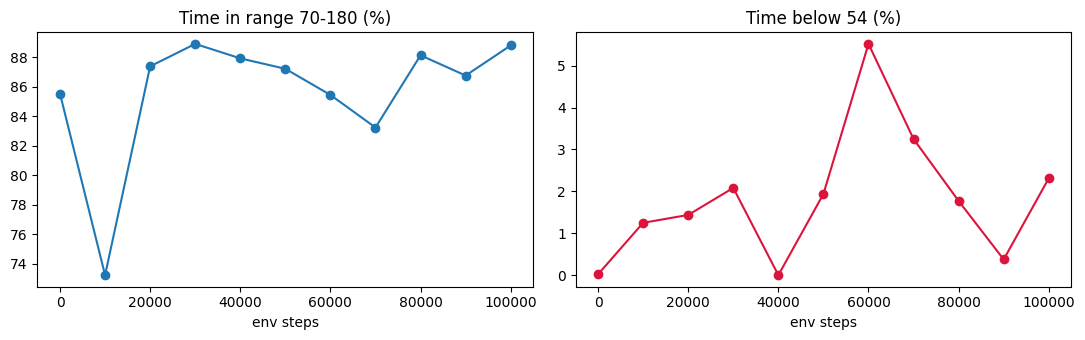

,step,TIR,TBR54,TBR70,TAR180,TAR250,mean_BG,CV,mean_risk,override_rate,n_terminated,wall_min
0,0,85.5208,0.0208,1.4792,13.0000,0.0000,144.3608,19.0850,3.4585,5.6875,0,0.00
1,10000,73.2292,1.2500,4.2292,22.5417,0.0000,148.0918,24.0637,5.1119,8.6042,0,3.71
2,20000,87.3750,1.4375,3.5208,9.1042,0.2708,139.9485,21.8876,3.6050,7.7917,0,7.39
3,30000,88.8958,2.0833,3.5833,7.5208,0.0000,132.1937,23.9546,3.6660,11.6250,0,10.94
4,40000,87.9167,0.0000,3.2708,8.8125,0.0000,128.4834,24.8863,3.0129,14.1667,0,14.44
5,50000,87.2083,1.9375,4.9583,7.8333,0.0000,128.5133,26.4061,3.5607,15.2500,0,18.04
6,60000,85.4375,5.5208,11.6458,2.9167,0.0000,111.6151,29.3494,5.2065,24.5625,0,21.62
7,70000,83.2292,3.2500,8.7500,8.0208,0.2708,122.1461,28.8988,4.3177,19.4375,0,25.21
8,80000,88.1250,1.7708,4.5208,7.3542,0.0000,124.5559,25.8788,3.3093,16.3958,0,28.64
9,90000,86.7500,0.3750,3.1250,10.1250,0.0000,134.8572,24.1188,3.2384,11.0000,0,32.06


In [ ]:
import pandas as pd, matplotlib.pyplot as plt
c = pd.read_csv(f"{DRIVE_ROOT}/results/{AGENT}/run_{RUN}/curve.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(c.step, c.TIR, marker="o"); ax[0].set_title("Time in range 70-180 (%)"); ax[0].set_xlabel("env steps")
ax[1].plot(c.step, c.TBR54, marker="o", color="crimson"); ax[1].set_title("Time below 54 (%)"); ax[1].set_xlabel("env steps")
plt.tight_layout(); plt.show()
c